# “DeepXDE‑Powered PINN for 2‑D Oxygen Diffusion and Consumption in Tissue Slices”
Below is a complete, snippet that trains a Physics‑Informed Neural Network (PINN) with DeepXDE to solve a 2‑D diffusion‑consumption problem—a classic model for oxygen (or nutrient / morphogen) transport in a thin tissue slice.


**Biological context:**
A square tissue section $0\leq x, y \leq 1$ cm is continuously supplied with oxygen along the left‐hand edge $(x=0)$. Everywhere else, oxygen is consumed at first‑order rate $k$. The PINN recovers the steady‑state concentration field $c(x,y)$ from just the governing equation and boundary values—no mesh, no classical solver.







In [1]:
# Cell 0 — install DeepXDE (≈10 s)
!pip install --quiet deepxde matplotlib

# Cell 1 — imports + backend
import deepxde as dde
import numpy as np
import matplotlib.pyplot as plt
dde.backend.set_default_backend("tensorflow")     # or "pytorch", "jax"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.3/192.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 4.3 MB/s eta 0:00:00
No backend selected.
Finding available backend...


Using backend: tensorflow.compat.v1
Other supported backends: tensorflow, pytorch, jax, paddle.
paddle supports more examples now and is recommended.
Instructions for updating:
non-resource variables are not supported in the long term


Found tensorflow.compat.v1
Setting the default backend to "tensorflow.compat.v1". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)
Setting the default backend to "tensorflow". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


# 1. Problem Setup
**Steady‑state 2‑D diffusion with decay:**
$$D\left( \frac{\partial^2 c}{\partial x^2} + \frac{\partial^2 c}{\partial y^2} \right) - k c = 0, \quad (x, y) \in [0, 1]^2.$$

**Boundary conditions:**
$$c(0, y) = c_0 \quad \text{(source)}, \qquad c(1, y) = c(x, 0) = c(x, 1) = 0 \quad \text{(sinks)}.$$


**Parameters used:**  $D = 1.0, k = 0.1, c_0 = 1.$


# 2. Define geometry, PDE & data in DeepXDE


In [2]:
# Cell 2
D, k, c0 = 1.0, 0.1, 1.0
geom = dde.geometry.Rectangle([0, 0], [1, 1])

# PDE residual (steady state)
def pde(x, c):
    dc_xx = dde.grad.hessian(c, x, component=0, i=0)   # ∂²c/∂x²
    dc_yy = dde.grad.hessian(c, x, component=0, i=1)   # ∂²c/∂y²
    return D * (dc_xx + dc_yy) - k * c

# Dirichlet BCs
bc_left   = dde.DirichletBC(geom, lambda x: c0, lambda x, on_b: on_b and np.isclose(x[0], 0.0))
bc_other  = dde.DirichletBC(geom, lambda x: 0.0,
                            lambda x, on_b: on_b and not np.isclose(x[0], 0.0))

data = dde.data.PDE(
    geom,
    pde,
    [bc_left, bc_other],
    num_domain    = 4000,   # interior collocation pts
    num_boundary  = 800     # boundary pts
)


# 3  Build & train the network



In [3]:
# Cell 3
net = dde.nn.FNN([2] + [128]*5 + [1], "tanh", "Glorot normal")
model = dde.Model(data, net)

model.compile("adam", lr=1e-3)
model.train(epochs=10000, display_every=1000)

# Optional fine‑tune
model.compile("L-BFGS")
model.train()


Compiling model...
Building feed-forward neural network...
'build' took 0.108471 s

'compile' took 0.838104 s

Training model...

Step      Train loss                        Test loss                         Test metric
0         [1.91e-04, 6.79e-01, 3.37e-02]    [1.91e-04, 6.79e-01, 3.37e-02]    []  
1000      [1.28e-03, 2.82e-02, 4.82e-02]    [1.28e-03, 2.82e-02, 4.82e-02]    []  
2000      [5.74e-04, 9.33e-03, 2.33e-02]    [5.74e-04, 9.33e-03, 2.33e-02]    []  
3000      [9.08e-04, 7.89e-03, 2.13e-02]    [9.08e-04, 7.89e-03, 2.13e-02]    []  
4000      [3.49e-04, 6.35e-03, 2.02e-02]    [3.49e-04, 6.35e-03, 2.02e-02]    []  
5000      [2.03e-04, 5.36e-03, 1.71e-02]    [2.03e-04, 5.36e-03, 1.71e-02]    []  
6000      [1.86e-02, 6.11e-03, 1.69e-02]    [1.86e-02, 6.11e-03, 1.69e-02]    []  
7000      [1.07e-03, 6.38e-03, 1.60e-02]    [1.07e-03, 6.38e-03, 1.60e-02]    []  
8000      [1.64e-04, 4.50e-03, 1.39e-02]    [1.64e-04, 4.50e-03, 1.39e-02]    []  
9000      [1.88e-03, 7.72e-03, 1.

(<deepxde.model.LossHistory at 0x7c82104b98d0>,
 <deepxde.model.TrainState at 0x7c82104ba3d0>)

# 4  Visualise the learned field

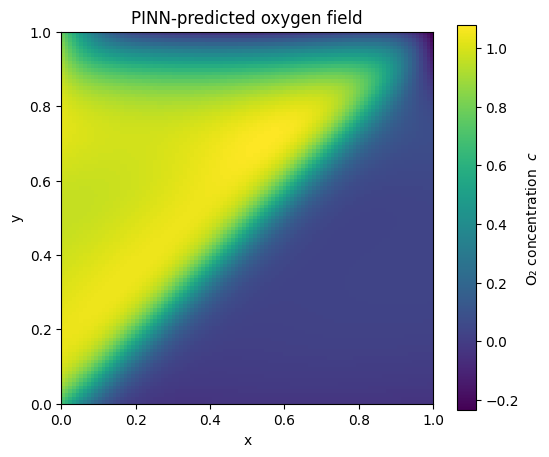

In [4]:
# Cell 4 — generate a 101×101 grid for plotting
xs = np.linspace(0, 1, 101)
ys = np.linspace(0, 1, 101)
X, Y = np.meshgrid(xs, ys)
XY = np.hstack((X.flatten()[:,None], Y.flatten()[:,None]))
C_pred = model.predict(XY).reshape(101, 101)

plt.figure(figsize=(6,5))
plt.imshow(C_pred, origin="lower", extent=[0,1,0,1], cmap="viridis")
plt.colorbar(label="O₂ concentration  $c$")
plt.title("PINN‑predicted oxygen field")
plt.xlabel("x"); plt.ylabel("y")
plt.show()
